# 01 — EDA & Data Cleaning
**Lumen Data Science — Cross-Sell & Up-Sell Prediction**

Ovaj notebook pokriva:
1. Učitavanje i osnovni pregled podataka
2. Analizu stupaca — što zadržati, što baciti
3. Analizu nedostajućih vrijednosti
4. Čišćenje redova i outliera
5. Enkodiranje kategoričkih varijabli
6. Inženjering novih značajki (feature engineering)
7. Spremanje očišćenog dataseta

In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
import os

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.4f}'.format)
plt.rcParams['figure.figsize'] = (12, 5)
sns.set_theme(style='whitegrid')

print('Libraries loaded ✓')

Libraries loaded ✓


---
## 1. Učitavanje podataka


In [40]:
import os

raw_path = '../data/raw/LUMEN_DS.csv'
converted_path = '../data/raw/data.csv'

if not os.path.exists(converted_path):
    with open(raw_path, 'r', encoding='utf-16') as file:
        data = file.read()
    
    data = data.replace('"', '')
    
    with open(converted_path, 'w', encoding='utf-8') as file:
        file.write(data)
    
    print('Konverzija gotova -> data.csv')
else:
    print('data.csv već postoji, preskačem konverziju')

data.csv već postoji, preskačem konverziju


In [41]:
DATE_COLS = [
    'Invoice Date',
    'Order Date',
    'Customer First Invoice Date',
    'Price last modified date in the ERP',
    'Born on date'
]

df_raw = pd.read_csv(
    '../data/raw/data.csv',
    encoding='utf-8',
    sep='|',
    low_memory=False,
    parse_dates=DATE_COLS
)

print(f'Shape: {df_raw.shape}')
print(f'Redova: {df_raw.shape[0]:,} | Stupaca: {df_raw.shape[1]}')
df_raw.head(3)

Shape: (1294962, 33)
Redova: 1,294,962 | Stupaca: 33


,Manufacturing Region,Manufacturing Location Code,Intercompany,CustomerID,Customer industry,Customer Region,Customer First Invoice Date,Top Customer Group,Item Code,Product family,Product group,Price last modified date in the ERP,Born on date,Make vs Buy,Sales Channel - Internal,Sales Channel - External,Sales Channel - Grouping,Invoice Date,Invoice #,Invoice Line #,Order Date,Order #,Order Line #,Invoiced qty (shipped),Ordered qty,Invoiced price,Invoiced price (TX),Cost of part,Material cost of part,Labor cost of part,Overhead cost of part,GM%,# of unique products on a quote
0,North America,N7,YES,224224,IC000,Asia,2009-06-26,OTHER,054501,PF002,NaN,NaT,2012-02-13,BUY,099,099,NaN,2019-08-06,16782381,18645771,2019-08-05,32606.0000,15791584.0000,499.0000,499.0000,0.3900,0.3900,0.4173,0.3900,0.0000,0.0000,-0.0700,1.0000
1,North America,N7,NO,230494,IC012,North America,2007-08-08,OTHER,034903,PF002,PC026,2020-06-22,2009-12-31,BUY,900,900,NaN,2019-11-26,16808190,18670413,2019-11-24,82915.0000,15806968.0000,1000.0000,1000.0000,0.1400,0.1400,0.0257,0.0240,0.0000,0.0000,0.8164,3.0000
2,Asia,N13,YES,235861,IC000,North America,2008-02-07,OTHER,057280,PF002,NaN,NaT,2017-01-03,MANUFACTURED,RS-NH,RS-NH,NaN,2019-09-24,16790722,18655474,2019-09-03,32787.0000,15795161.0000,3.0000,3.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,NaN,14.0000


In [42]:
already_dropped = [
    'Invoice Line #', 'Order Date', 'Ordered qty',
    'Material cost of part', 'Labor cost of part', 'Overhead cost of part',
    'Sales Channel - Grouping', 'Born on date',
    'Price last modified date in the ERP',
    '# of unique products on a quote', 'Order Line #', 'Order #'
]

display(df_raw[already_dropped].head(20))

,Invoice Line #,Order Date,Ordered qty,Material cost of part,Labor cost of part,Overhead cost of part,Sales Channel - Grouping,Born on date,Price last modified date in the ERP,# of unique products on a quote,Order Line #,Order #
0,18645771,2019-08-05,499.0000,0.3900,0.0000,0.0000,NaN,2012-02-13,NaT,1.0000,15791584.0000,32606.0000
1,18670413,2019-11-24,1000.0000,0.0240,0.0000,0.0000,NaN,2009-12-31,2020-06-22,3.0000,15806968.0000,82915.0000
2,18655474,2019-09-03,3.0000,0.0000,0.0000,0.0000,NaN,2017-01-03,NaT,14.0000,15795161.0000,32787.0000
3,18688647,2020-03-10,5000.0000,0.0000,0.0000,0.0000,NaN,2014-12-02,NaT,1.0000,15818226.0000,98093.0000
4,18688639,2020-03-10,5000.0000,0.0000,0.0000,0.0000,NaN,2014-12-02,NaT,1.0000,15818226.0000,98093.0000
5,18687466,2020-03-10,5000.0000,0.0000,0.0000,0.0000,NaN,2014-12-02,NaT,1.0000,15818226.0000,98093.0000
6,18581670,2018-07-06,4000.0000,0.0000,0.0000,0.0000,NaN,2014-12-09,NaT,6.0000,15736930.0000,513470.0000
7,18717648,2019-11-18,15000.0000,0.0000,0.0000,0.0000,NaN,2014-02-12,NaT,1.0000,15805892.0000,73572.0000
8,18678512,2019-12-05,500.0000,0.0000,0.0000,0.0000,NaN,2014-07-18,NaT,1.0000,15808552.0000,91617.0000
9,18632400,2019-01-14,2000.0000,0.0000,0.0000,0.0000,NaN,2015-07-21,NaT,2.0000,15764662.0000,526717.0000


---
## 2. Osnovni pregled — dtypes, nullovi, unike

In [43]:
# Pregled svakog stupca: dtype, % nullova, broj unikatnih vrijednosti
summary = pd.DataFrame({
    'dtype': df_raw.dtypes,
    'null_count': df_raw.isnull().sum(),
    'null_%': (df_raw.isnull().sum() / len(df_raw) * 100).round(2),
    'n_unique': df_raw.nunique(),
    'sample_value': df_raw.iloc[0],
    'zero': df_raw.eq(0).sum(),
    'zero_%': (df_raw.eq(0).sum() / len(df_raw) * 100).round(2)
})
display(summary)

,dtype,null_count,null_%,n_unique,sample_value,zero,zero_%
Manufacturing Region,str,40509,3.1300,3,North America,0,0.0000
Manufacturing Location Code,str,39959,3.0900,29,N7,0,0.0000
Intercompany,str,0,0.0000,2,YES,0,0.0000
CustomerID,int64,0,0.0000,12214,224224,0,0.0000
Customer industry,str,0,0.0000,15,IC000,0,0.0000
Customer Region,str,103,0.0100,3,Asia,0,0.0000
Customer First Invoice Date,datetime64[us],0,0.0000,4232,2009-06-26 00:00:00,0,0.0000
Top Customer Group,str,0,0.0000,2,OTHER,0,0.0000
Item Code,str,55,0.0000,63019,054501,0,0.0000
Product family,str,0,0.0000,3,PF002,0,0.0000


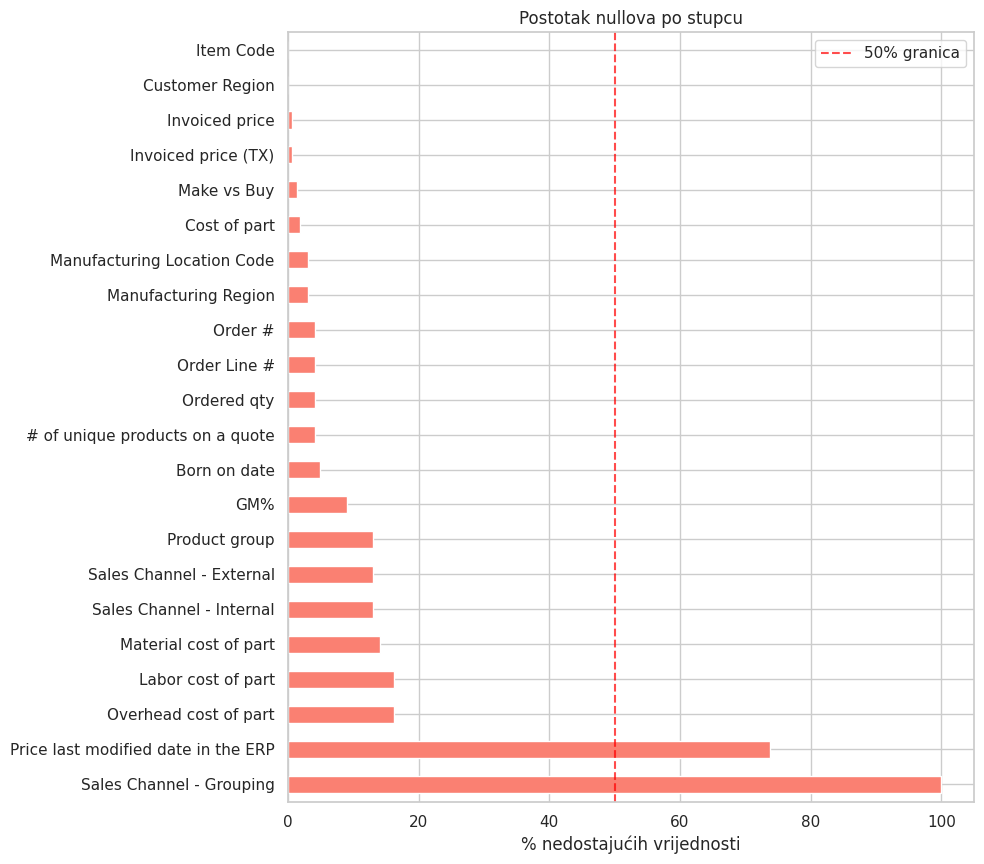

In [44]:
# Vizualizacija % nullova po stupcu
null_pct = (df_raw.isnull().sum() / len(df_raw) * 100).sort_values(ascending=False)
null_pct = null_pct[null_pct > 0]

if len(null_pct) > 0:
    fig, ax = plt.subplots(figsize=(10, max(4, len(null_pct) * 0.4)))
    null_pct.plot(kind='barh', ax=ax, color='salmon')
    ax.set_xlabel('% nedostajućih vrijednosti')
    ax.set_title('Postotak nullova po stupcu')
    ax.axvline(50, color='red', linestyle='--', alpha=0.7, label='50% granica')
    ax.legend()
    plt.tight_layout()
    plt.show()
else:
    print('Nema nullova — provjeri jesu li prazni stringovi umjesto NaN!')

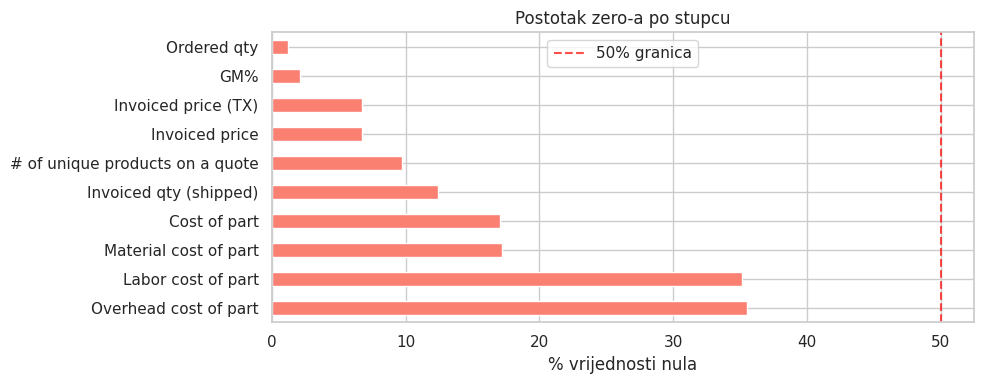

In [45]:
# Vizualizacija % zero-a po stupcu
zero_pct = (df_raw.eq(0).sum() / len(df_raw) * 100).sort_values(ascending=False)
zero_pct = zero_pct[zero_pct > 0]

if len(zero_pct) > 0:
    fig, ax = plt.subplots(figsize=(10, max(4, len(zero_pct) * 0.4)))
    zero_pct.plot(kind='barh', ax=ax, color='salmon')
    ax.set_xlabel('% vrijednosti nula')
    ax.set_title('Postotak zero-a po stupcu')
    ax.axvline(50, color='red', linestyle='--', alpha=0.7, label='50% granica')
    ax.legend()
    plt.tight_layout()
    plt.show()
else:
    print('Nema zero-a!')

In [46]:
# Provjeri prazne stringove (čest problem u ovom datasetu)
empty_str = (df_raw == '').sum()
empty_str = empty_str[empty_str > 0]
print('Stupci s praznim stringovima:')
print(empty_str.sort_values(ascending=False))

Stupci s praznim stringovima:
Series([], dtype: int64)


---
## 3. Uklanjanje stupaca (nastavak od cleaner.py)

Prijateljev cleaner.py već je uklonio stupce koji su redudantni ili previše granularni.
Ovdje razmatramo treba li još nešto ukloniti.

In [47]:
# Stupci koje je cleaner.py uklonio, ali malo editano
already_dropped = [
    'Invoice Line #', 'Order Date',
    'Material cost of part', 'Labor cost of part', 'Overhead cost of part',
    'Sales Channel - Grouping', 'Born on date',
    'Price last modified date in the ERP', 'Order Line #', 'Order #', '# of unique products on a quote'
]

# Primijeni drop (samo ako stupci postoje u df_raw)
cols_to_drop = [c for c in already_dropped if c in df_raw.columns]
df = df_raw.drop(columns=cols_to_drop)
print(f'Nakon inicijalnog dropa: {df.shape}')

Nakon inicijalnog dropa: (1294962, 22)


In [48]:
# --- ANALIZA PREOSTALIH STUPACA ---
# Pogledaj kardinalnost kategoričkih stupaca
cat_cols = df.select_dtypes(include='object').columns.tolist()

for col in cat_cols:
    vc = df[col].value_counts(dropna=False)
    print(f'\n=== {col} ({df[col].nunique()} unikatnih) ===')
    print(vc.head(10))


=== Manufacturing Region (3 unikatnih) ===
Manufacturing Region
North America    734815
Asia             464038
Europe            55600
NaN               40509
Name: count, dtype: int64

=== Manufacturing Location Code (29 unikatnih) ===
Manufacturing Location Code
B6     199828
B8     151245
N13    124771
B77    103285
B20     99905
B70     89945
L1      67043
L2      59951
B3      54164
B76     46967
Name: count, dtype: int64


/tmp/ipykernel_2890/1521944361.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include='object').columns.tolist()



=== Intercompany (2 unikatnih) ===
Intercompany
NO     1103993
YES     190969
Name: count, dtype: int64

=== Customer industry (15 unikatnih) ===
Customer industry
IC000    453233
IC007    183975
IC008    175248
IC003    103123
IC005     96904
IC004     64220
IC011     59069
IC010     49535
IC009     37024
IC002     28634
Name: count, dtype: int64

=== Customer Region (3 unikatnih) ===
Customer Region
North America    773408
Asia             439883
Europe            81568
NaN                 103
Name: count, dtype: int64

=== Top Customer Group (2 unikatnih) ===
Top Customer Group
OTHER    1197621
STAR       97341
Name: count, dtype: int64

=== Item Code (63019 unikatnih) ===
Item Code
BOY485-NPI         15916
/C                  8356
TRANSPORTKOSTEN     7947
644138              5305
/LTI                4265
SMSKID              3707
2004                2938
SAMPLE DEBIT        2926
46000               2762
312-EKD             2440
Name: count, dtype: int64

=== Product family (3 unika

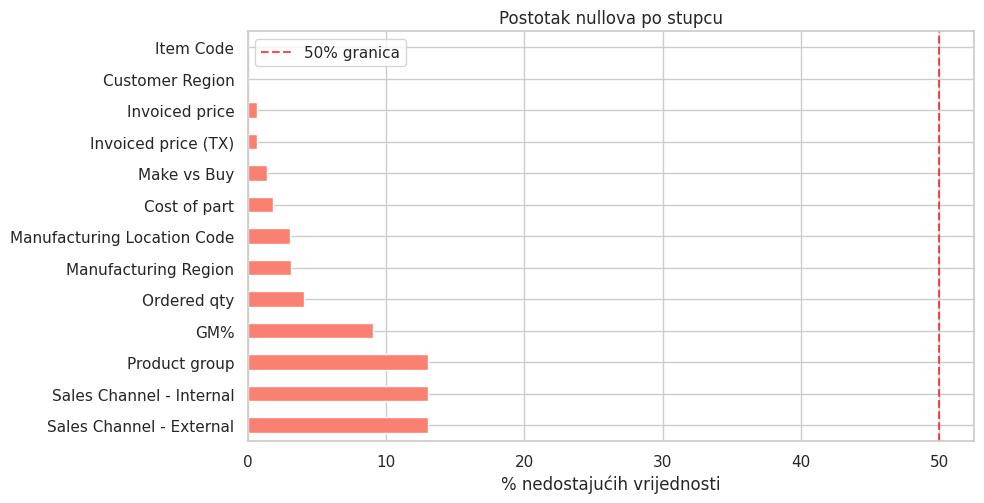

In [49]:
# Vizualizacija % nullova po stupcu
null_pct = (df.isnull().sum() / len(df) * 100).sort_values(ascending=False)
null_pct = null_pct[null_pct > 0]

if len(null_pct) > 0:
    fig, ax = plt.subplots(figsize=(10, max(4, len(null_pct) * 0.4)))
    null_pct.plot(kind='barh', ax=ax, color='salmon')
    ax.set_xlabel('% nedostajućih vrijednosti')
    ax.set_title('Postotak nullova po stupcu')
    ax.axvline(50, color='red', linestyle='--', alpha=0.7, label='50% granica')
    ax.legend()
    plt.tight_layout()
    plt.show()
else:
    print('Nema nullova — provjeri jesu li prazni stringovi umjesto NaN!')

In [50]:
# Intercompany transakcije — treba li ih filtrirati?
# Intercompany = YES znači prodaja unutar iste korporacije, ne pravi kupac
print('Raspodjela Intercompany:')
print(df['Intercompany'].value_counts())
print(f'\n% Intercompany=YES: {(df["Intercompany"]=="YES").mean()*100:.1f}%')

# ODLUKA: Filtriraj intercompany van za cross-sell model
# (ostavi ih za posebnu analizu ako treba)
df_external = df[df['Intercompany'] == 'NO'].copy()
print(f'\nNakon filtriranja Intercompany=YES: {df_external.shape}')

Raspodjela Intercompany:
Intercompany
NO     1103993
YES     190969
Name: count, dtype: int64

% Intercompany=YES: 14.7%

Nakon filtriranja Intercompany=YES: (1103993, 22)


In [51]:
# Sales Channel - Internal vs External — jesu li isti?
same_channel = (df['Sales Channel - Internal'] == df['Sales Channel - External']).mean()
print(f'% redova gdje su Internal == External kanal: {same_channel*100:.1f}%')
# Ako je > 95%, jedan od njih je redundantan

# PRIJEDLOG: ako su gotovo uvijek isti, zadrži samo Internal i dropaj External
# df = df.drop(columns=['Sales Channel - External'])  # odkomentiraj ako potvrdiš

% redova gdje su Internal == External kanal: 86.9%


In [52]:
display(df[['Sales Channel - Internal', 'Sales Channel - External']].head(20))

,Sales Channel - Internal,Sales Channel - External
0,099,099
1,900,900
2,RS-NH,RS-NH
3,230,230
4,230,230
5,230,230
6,230,230
7,11103,11103
8,11103,11103
9,DG_0029,DG_0029


In [53]:
# Manufacturing Location Code vs Manufacturing Region — hijerarhija?
print(df.groupby('Manufacturing Region')['Manufacturing Location Code'].nunique())
# Ako Region ima malo unikata a Location Code mnogo — Location Code je granularniji
# Za modele često je dovoljno Region razina

Manufacturing Region
Asia             11
Europe            3
North America    14
Name: Manufacturing Location Code, dtype: int64


---
## 4. Čišćenje redova

In [54]:
df_4 = df_external.copy()

print(df_4.columns.tolist())

['Manufacturing Region', 'Manufacturing Location Code', 'Intercompany', 'CustomerID', 'Customer industry', 'Customer Region', 'Customer First Invoice Date', 'Top Customer Group', 'Item Code', 'Product family', 'Product group', 'Make vs Buy', 'Sales Channel - Internal', 'Sales Channel - External', 'Invoice Date', 'Invoice #', 'Invoiced qty (shipped)', 'Ordered qty', 'Invoiced price', 'Invoiced price (TX)', 'Cost of part', 'GM%']


In [55]:
# Pregled svakog stupca: dtype, % nullova, broj unikatnih vrijednosti
summary_4 = pd.DataFrame({
    'dtype': df_4.dtypes,
    'null_count': df_4.isnull().sum(),
    'null_%': (df_4.isnull().sum() / len(df_4) * 100).round(2),
    'n_unique': df_4.nunique(),
    'sample_value': df_4.iloc[0],
    'zero': df_4.eq(0).sum(),
    'zero_%': (df_4.eq(0).sum() / len(df_4) * 100).round(2)
})
display(summary)

,dtype,null_count,null_%,n_unique,sample_value,zero,zero_%
Manufacturing Region,str,40509,3.1300,3,North America,0,0.0000
Manufacturing Location Code,str,39959,3.0900,29,N7,0,0.0000
Intercompany,str,0,0.0000,2,YES,0,0.0000
CustomerID,int64,0,0.0000,12214,224224,0,0.0000
Customer industry,str,0,0.0000,15,IC000,0,0.0000
Customer Region,str,103,0.0100,3,Asia,0,0.0000
Customer First Invoice Date,datetime64[us],0,0.0000,4232,2009-06-26 00:00:00,0,0.0000
Top Customer Group,str,0,0.0000,2,OTHER,0,0.0000
Item Code,str,55,0.0000,63019,054501,0,0.0000
Product family,str,0,0.0000,3,PF002,0,0.0000


In [56]:
# 4a. Ukloni redove bez ključnih identifikatora
before = len(df_4)
df = df_4.dropna(subset=['Item Code', 'CustomerID'])
print(f'Uklonjeno zbog null ključnih stupaca: {before - len(df)} redova')

Uklonjeno zbog null ključnih stupaca: 50 redova


In [57]:
df_4 = df_4.dropna(subset=['Item Code', 'CustomerID'])
print(f'Uklonjeno zbog null ključnih stupaca: {before - len(df_4)} redova')

Uklonjeno zbog null ključnih stupaca: 50 redova


In [58]:
bad_price = df_4['Invoiced price'].isna() | (df_4['Invoiced price'] == 0)
print(f'Ukupno redova bez prave cijene: {bad_price.sum():,}')
print(f'  - null: {df_4["Invoiced price"].isna().sum():,}')
print(f'  - zero: {(df_4["Invoiced price"] == 0).sum():,}')
print(f'  - negativne (zasebno rješavamo): {(df_4["Invoiced price"] < 0).sum():,}')
print(f'\nTo je {bad_price.mean()*100:.1f}% dataseta')
 

Ukupno redova bez prave cijene: 69,296
  - null: 8,518
  - zero: 60,778
  - negativne (zasebno rješavamo): 549

To je 6.3% dataseta


In [59]:
sample_slash_mask = df_4['Item Code'].str.contains(r'SAMPLE|^/', na=False)
 
print('=== SAMPLE i slash (/) item codeovi — pregled ===\n')
print(f'Ukupno redova: {sample_slash_mask.sum():,}')
print(f'Unique item codeova: {df_4[sample_slash_mask]["Item Code"].nunique()}')
 
# Koliko ih ima pravu cijenu, koliko ne?
ss_with_price = (df_4[sample_slash_mask]['Invoiced price'] > 0).sum()
ss_without_price = (
    df_4[sample_slash_mask]['Invoiced price'].isna() | 
    (df_4[sample_slash_mask]['Invoiced price'] == 0)
).sum()
print(f'\nRedova s cijenom > 0: {ss_with_price:,} ({ss_with_price/sample_slash_mask.sum()*100:.1f}%)')
print(f'Redova s null/zero cijenom: {ss_without_price:,} ({ss_without_price/sample_slash_mask.sum()*100:.1f}%)')
 
# Breakdown po item codeu
ss_stats = (
    df_4[sample_slash_mask]
    .groupby('Item Code')
    .agg(
        total=('Invoiced price', 'size'),
        has_price=('Invoiced price', lambda x: (x > 0).sum())
    )
)
ss_stats['pct_with_price'] = (ss_stats['has_price'] / ss_stats['total'] * 100).round(1)
ss_stats = ss_stats.sort_values('total', ascending=False)
 
print('\nBreakdown po item codeu:')
display(ss_stats)

=== SAMPLE i slash (/) item codeovi — pregled ===

Ukupno redova: 16,535
Unique item codeova: 92

Redova s cijenom > 0: 1,702 (10.3%)
Redova s null/zero cijenom: 14,833 (89.7%)

Breakdown po item codeu:


,total,has_price,pct_with_price
Item Code,,,
/C,8319,0,0.0000
/LTI,4251,0,0.0000
SAMPLE-MPCS,970,442,45.6000
SAMPLE-EACH,660,198,30.0000
BOY485-SAMPLES,469,44,9.4000
...,...,...,...
SAMPLE-EZ BRA,1,0,0.0000
"SAMPLE-CONVERTERS, INC.",1,0,0.0000
SAMPLE-NipEAZE,1,1,100.0000


In [60]:
# Za SVAKI item code: koliki % svih redova ima pravu cijenu?
item_stats = df_4.groupby('Item Code').agg(
    total=('Invoiced price', 'size'),
    has_price=('Invoiced price', lambda x: (x > 0).sum())
)
item_stats['pct'] = item_stats['has_price'] / item_stats['total']
 
# Sensitivity — koliko redova spašavamo po pragu?
print('=== Sensitivity check — threshold vs. broj redova ===\n')
for t in [0.1, 0.3, 0.5, 0.7, 0.9]:
    imputable = item_stats[item_stats['pct'] >= t].index
    n_saved = df_4[bad_price & df_4['Item Code'].isin(imputable)].shape[0]
    n_deleted = bad_price.sum() - n_saved
    n_items_saved = df_4.loc[bad_price & df_4['Item Code'].isin(imputable), 'Item Code'].nunique()
    n_items_deleted = df_4.loc[bad_price & ~df_4['Item Code'].isin(imputable), 'Item Code'].nunique()
    print(f'  Threshold {t:.0%}: impute {n_saved:>6,} redova ({n_items_saved:>3} itema) | '
          f'delete {n_deleted:>6,} redova ({n_items_deleted:>3} itema)')

=== Sensitivity check — threshold vs. broj redova ===

  Threshold 10%: impute 18,831 redova (5400 itema) | delete 50,465 redova (4108 itema)
  Threshold 30%: impute 15,913 redova (5315 itema) | delete 53,383 redova (4193 itema)
  Threshold 50%: impute 12,464 redova (5132 itema) | delete 56,832 redova (4376 itema)
  Threshold 70%: impute  9,414 redova (4026 itema) | delete 59,882 redova (5482 itema)
  Threshold 90%: impute  4,748 redova (2498 itema) | delete 64,548 redova (7010 itema)


In [61]:
THRESHOLD = 0.5  # <-- prilagodi nakon sensitivity checka
# ili bi cak stavio 0.7
 
imputable_items = item_stats[item_stats['pct'] >= THRESHOLD].index
 
# Medijan SAMO od pozitivnih cijena
median_price = (
    df_4[df_4['Invoiced price'] > 0]
    .groupby('Item Code')['Invoiced price']
    .median()
)
 
# Impute gdje možemo
impute_mask = bad_price & df_4['Item Code'].isin(imputable_items)
df_4.loc[impute_mask, 'Invoiced price'] = (
    df_4.loc[impute_mask, 'Item Code'].map(median_price)
)
print(f'Imputirano: {impute_mask.sum():,} redova ({df_4.loc[impute_mask, "Item Code"].nunique()} itema)')
 
# Obriši gdje ne možemo
delete_mask = bad_price & ~df_4['Item Code'].isin(imputable_items)
print(f'Brisanje: {delete_mask.sum():,} redova ({df_4.loc[delete_mask, "Item Code"].nunique()} itema)')
print(f'\nTop 20 obrisanih item codeova:')
print(df_4[delete_mask]['Item Code'].value_counts().head(20))
 
before = len(df_4)
df_4 = df_4[~delete_mask]
print(f'\nShape: {before:,} → {len(df_4):,} (obrisano {before - len(df_4):,})')

Imputirano: 12,464 redova (5132 itema)
Brisanje: 56,832 redova (4376 itema)

Top 20 obrisanih item codeova:
Item Code
/C                  8319
TRANSPORTKOSTEN     7815
/LTI                4251
SMSKID              3695
LGMC-000203          652
SAMPLE-MPCS          528
SAMPLE-EACH          462
BOY485-SAMPLES       425
AUSFA                401
BOY485-LASER         325
*200005              295
SAMPLE               270
BOY485-JETSON        186
DEL449-YC553-1       165
NEUBS                156
PROGRAMM             155
DEL449-31FGN-1       126
DEL449-1888601       126
DEL449-1051501-9     126
SAMPLE-ROLLS         126
Name: count, dtype: int64

Shape: 1,103,943 → 1,047,111 (obrisano 56,832)


In [62]:
surviving_ss = df_4[df_4['Item Code'].str.contains(r'SAMPLE|^/', na=False)]
 
print('=== Sanity check — SAMPLE i slash item codeovi nakon imputacije ===\n')
print(f'Preživjelo redova: {len(surviving_ss):,}')
print(f'Unique item codeova: {surviving_ss["Item Code"].nunique()}')
 
if len(surviving_ss) > 0:
    ss_surv = (
        surviving_ss
        .groupby('Item Code')
        .agg(
            rows=('Invoiced price', 'size'),
            median_price=('Invoiced price', 'median'),
            min_price=('Invoiced price', 'min'),
            max_price=('Invoiced price', 'max')
        )
        .sort_values('rows', ascending=False)
    )
    print('\nPreživjeli SAMPLE/slash itemi:')
    display(ss_surv)
    print('\nAko ovo izgleda sumnjivo, razmisli o ručnom dropu.')
else:
    print('Nijedan SAMPLE/slash item nije preživio — čisto! ✓')
 
# Finalna provjera: ima li još null/zero cijena?
remaining = df_4['Invoiced price'].isna() | (df_4['Invoiced price'] == 0)
print(f'\nPreostalo redova s null/zero cijenom: {remaining.sum()}')

=== Sanity check — SAMPLE i slash item codeovi nakon imputacije ===

Preživjelo redova: 1,775
Unique item codeova: 56

Preživjeli SAMPLE/slash itemi:


,rows,median_price,min_price,max_price
Item Code,,,,
SAMPLE-MPCS,442,375.0000,0.0047,24000.0000
/05,303,0.1500,0.0150,0.5000
/03,204,0.0015,0.0010,0.1500
SAMPLE-EACH,198,1.2500,0.0010,300.0000
/04,103,0.0150,0.0150,0.0150
SAMPLE DEBIT,103,0.1625,0.0319,38.0000
SAMPLE-NEWNAN,102,20.0000,0.2700,1390.0000
/ENGINEERING-N,73,2227.5000,220.0000,19220.0000
BOY485-SAMPLES,44,15.0000,0.1000,4500.0000



Ako ovo izgleda sumnjivo, razmisli o ručnom dropu.

Preostalo redova s null/zero cijenom: 0


In [63]:
# Za Invoiced price < 0
print(f'Redova s Invoiced price < 0: {(df_4["Invoiced price"] < 0).sum()}')
display(df_4[df_4['Invoiced price'] < 0].head(10))

Redova s Invoiced price < 0: 549


,Manufacturing Region,Manufacturing Location Code,Intercompany,CustomerID,Customer industry,Customer Region,Customer First Invoice Date,Top Customer Group,Item Code,Product family,Product group,Make vs Buy,Sales Channel - Internal,Sales Channel - External,Invoice Date,Invoice #,Invoiced qty (shipped),Ordered qty,Invoiced price,Invoiced price (TX),Cost of part,GM%
29223,North America,N7,NO,216863,IC008,North America,2020-01-10,OTHER,032647,PF002,PC013,BUY,AL-01,AL-01,2020-01-10,4777653,24.6000,24.6000,-0.0102,-0.0102,1.9863,195.7353
33373,NaN,NaN,NO,279825,IC003,North America,2003-07-16,OTHER,46000,PF000,NaN,MANUFACTURED,DEW-NC,DEW-NC,2018-10-19,1208666,1.0000,1.0000,-36.6000,-36.6000,0.0000,1.0000
33374,NaN,NaN,NO,287422,IC003,North America,2003-07-08,OTHER,46000,PF000,NaN,MANUFACTURED,SA-NC,SA-NC,2018-11-05,1161143,1.0000,1.0000,-9.1900,-9.1900,0.0000,1.0000
33531,NaN,NaN,NO,287422,IC003,North America,2003-07-08,OTHER,46000,PF000,NaN,MANUFACTURED,SA-NC,SA-NC,2018-10-16,1161501,1.0000,1.0000,-9.6100,-9.6100,0.0000,1.0000
33532,NaN,NaN,NO,285880,IC000,North America,2017-11-02,OTHER,46000,PF000,NaN,MANUFACTURED,H,H,2018-11-27,1335118,1.0000,1.0000,-81.6600,-81.6600,0.0000,1.0000
33533,NaN,NaN,NO,284197,IC003,North America,2006-01-25,OTHER,46000,PF000,NaN,MANUFACTURED,DG-NC,DG-NC,2018-03-15,1227710,1.0000,1.0000,-8.7200,-8.7200,0.0000,1.0000
33542,NaN,NaN,NO,281386,IC003,North America,2011-08-09,OTHER,46000,PF000,NaN,MANUFACTURED,JG,JG,2019-03-29,1314266,1.0000,1.0000,-13.0100,-13.0100,0.0000,1.0000
33543,NaN,NaN,NO,285396,IC003,North America,2011-10-31,OTHER,46000,PF000,NaN,MANUFACTURED,TW,TW,2018-12-20,1317780,1.0000,1.0000,-62.8400,-62.8400,0.0000,1.0000
33545,NaN,NaN,NO,284294,IC003,North America,2004-06-16,OTHER,46000,PF000,NaN,MANUFACTURED,H,H,2018-07-11,1236921,1.0000,1.0000,-11.3900,-11.3900,0.0000,1.0000
33546,NaN,NaN,NO,285878,IC000,North America,2017-10-10,OTHER,46000,PF000,NaN,MANUFACTURED,H,H,2018-07-26,1334956,1.0000,1.0000,-42.8100,-42.8100,0.0000,1.0000


In [64]:
# Provjeri što je item code 46000
print(df_4[df_4['Item Code'] == '46000'][['Product family', 'Product group', 'Make vs Buy', 'Sales Channel - Internal']].value_counts().head(10))

# Ima li 46000 i normalnih (pozitivnih) transakcija?
print(f'\n46000 redova s cijenom > 0: {(df_4[df_4["Item Code"] == "46000"]["Invoiced price"] > 0).sum()}')
print(f'46000 redova s cijenom < 0: {(df_4[df_4["Item Code"] == "46000"]["Invoiced price"] < 0).sum()}')

# Kanal raspodjela negativnih
print('\nKanal raspodjela negativnih cijena:')
print(df_4[df_4['Invoiced price'] < 0]['Sales Channel - Internal'].value_counts().head(10))

Series([], Name: count, dtype: int64)

46000 redova s cijenom > 0: 2253
46000 redova s cijenom < 0: 508

Kanal raspodjela negativnih cijena:
Sales Channel - Internal
H         128
TW         84
JG         81
SA         49
DEW        35
DAO-NC     32
DEW-NC     28
ES         17
MW         15
DG         14
Name: count, dtype: int64


In [65]:
# Što su pozitivne 46000 transakcije
display(df_4[
    (df_4['Item Code'] == '46000') & 
    (df_4['Invoiced price'] > 0)
].head(5))

,Manufacturing Region,Manufacturing Location Code,Intercompany,CustomerID,Customer industry,Customer Region,Customer First Invoice Date,Top Customer Group,Item Code,Product family,Product group,Make vs Buy,Sales Channel - Internal,Sales Channel - External,Invoice Date,Invoice #,Invoiced qty (shipped),Ordered qty,Invoiced price,Invoiced price (TX),Cost of part,GM%
33365,NaN,NaN,NO,106730,IC009,North America,2016-09-08,OTHER,46000,PF000,NaN,MANUFACTURED,NP,NP,2020-01-31,1111295,1.0000,1.0000,15.3800,15.3800,0.0000,1.0000
33366,NaN,NaN,NO,106730,IC009,North America,2016-09-08,OTHER,46000,PF000,NaN,MANUFACTURED,NP,NP,2019-05-30,1109605,1.0000,1.0000,123.0900,123.0900,0.0000,1.0000
33367,NaN,NaN,NO,106730,IC009,North America,2016-09-08,OTHER,46000,PF000,NaN,MANUFACTURED,NP,NP,2019-05-30,1109604,1.0000,1.0000,28.3400,28.3400,0.0000,1.0000
33370,NaN,NaN,NO,289929,IC003,North America,2019-03-08,OTHER,46000,PF000,NaN,MANUFACTURED,NaN,NaN,2019-03-21,1335516,0.0000,1.0000,11.7700,11.7700,11.7700,0.0000
33389,NaN,NaN,NO,283252,IC003,North America,2014-04-21,OTHER,46000,PF000,NaN,MANUFACTURED,JG,JG,2019-05-22,1124620,0.0000,1.0000,111.3900,111.3900,66.3900,0.4040


In [66]:
before = len(df_4)
df_4 = df_4[df_4['Invoiced price'] >= 0]
print(f'Obrisano negativnih: {before - len(df_4)} redova')
print(f'Shape nakon: {df_4.shape}')

Obrisano negativnih: 549 redova
Shape nakon: (1046562, 22)


In [67]:
print(f'Shape: {df_4.shape}')
print(f'\nNullovi:')
print(df_4.isnull().sum()[df_4.isnull().sum() > 0])
print(f'\nPrazni stringovi:')
empty = (df_4 == '').sum()
print(empty[empty > 0])

Shape: (1046562, 22)

Nullovi:
Manufacturing Region           23632
Manufacturing Location Code    23090
Customer Region                   84
Product group                  49076
Make vs Buy                     4420
Sales Channel - Internal       22068
Sales Channel - External       22068
Ordered qty                    27294
Invoiced price (TX)                2
Cost of part                   20927
GM%                            32240
dtype: int64

Prazni stringovi:
Series([], dtype: int64)


In [68]:
print(f'Redova s Invoiced qty <= 0: {(df_4["Invoiced qty (shipped)"] <= 0).sum()}')
print(f'Redova s Invoiced qty < 0: {(df_4["Invoiced qty (shipped)"] < 0).sum()}')
print(f'Redova s Invoiced qty == 0: {(df_4["Invoiced qty (shipped)"] == 0).sum()}')

display(df_4[df_4['Invoiced qty (shipped)'] <= 0].head(5))

Redova s Invoiced qty <= 0: 114635
Redova s Invoiced qty < 0: 6
Redova s Invoiced qty == 0: 114629


,Manufacturing Region,Manufacturing Location Code,Intercompany,CustomerID,Customer industry,Customer Region,Customer First Invoice Date,Top Customer Group,Item Code,Product family,Product group,Make vs Buy,Sales Channel - Internal,Sales Channel - External,Invoice Date,Invoice #,Invoiced qty (shipped),Ordered qty,Invoiced price,Invoiced price (TX),Cost of part,GM%
129,North America,B20,NO,285757,IC003,North America,2016-02-26,OTHER,2-125-000-15776,PF001,PC010,MANUFACTURED,SA,SA,2018-10-19,1332363,0.0000,210.0000,11.7600,11.7600,8.2282,0.3003
130,North America,B20,NO,285757,IC003,North America,2016-02-26,OTHER,2-125-000-15776,PF001,PC010,MANUFACTURED,SA,SA,2018-09-24,1332362,0.0000,210.0000,11.7600,11.7600,8.2282,0.3003
132,North America,B20,NO,285396,IC003,North America,2011-10-31,OTHER,2-125-000-16104,PF001,PC001,MANUFACTURED,DGIFT,DGIFT,2020-03-12,17124990,0.0000,3.4000,0.3300,0.3300,0.1906,0.4224
133,North America,B20,NO,285396,IC003,North America,2011-10-31,OTHER,2-125-000-16104,PF001,PC001,MANUFACTURED,DGIFT,DGIFT,2020-03-12,17124991,0.0000,3.4000,0.3300,0.3300,0.1906,0.4224
136,North America,B20,NO,288928,IC003,North America,2008-04-24,OTHER,2-125-000-16179,PF001,PC010,MANUFACTURED,SA,SA,2019-04-26,1271002,0.0000,12.0000,35.7700,35.7700,19.1147,0.4656


In [69]:
print(f'Redova s Ordered qty <= 0: {(df_4["Ordered qty"] <= 0).sum()}')
print(f'Redova s Ordered qty < 0: {(df_4["Ordered qty"] < 0).sum()}')
print(f'Redova s Ordered qty == 0: {(df_4["Ordered qty"] == 0).sum()}')

display(df_4[df_4['Ordered qty'] <= 0].head(5))

Redova s Ordered qty <= 0: 2790
Redova s Ordered qty < 0: 5
Redova s Ordered qty == 0: 2785


,Manufacturing Region,Manufacturing Location Code,Intercompany,CustomerID,Customer industry,Customer Region,Customer First Invoice Date,Top Customer Group,Item Code,Product family,Product group,Make vs Buy,Sales Channel - Internal,Sales Channel - External,Invoice Date,Invoice #,Invoiced qty (shipped),Ordered qty,Invoiced price,Invoiced price (TX),Cost of part,GM%
666,North America,B20,NO,285751,IC003,North America,2016-01-28,OTHER,2-125-000-18620,PF001,PC010,MANUFACTURED,TW,TW,2019-08-22,1332254,0.0000,0.0000,55.0000,55.0000,16.1005,0.7073
1219,Asia,B77,NO,20750,IC007,Asia,2013-12-10,OTHER,DEL449-4758U37CI,PF001,PC010,MANUFACTURED,B318,B318,2018-12-27,13582500,500.0000,0.0000,0.4505,0.4505,0.2720,0.3962
3327,Asia,B76,NO,19415,IC008,Asia,2014-06-09,OTHER,DEL449-5340A08CI,PF001,PC010,MANUFACTURED,B318,B318,2018-08-20,15356136,7263.0000,0.0000,0.3703,0.3703,0.2753,0.2565
5822,North America,L1,NO,1849,IC002,North America,2011-01-04,OTHER,/03,PF001,NaN,NaN,0076,0076,2018-12-14,4556047,209100.0000,0.0000,0.0045,0.0045,0.0000,1.0000
6609,North America,B20,NO,285154,IC003,North America,2009-08-06,OTHER,2-160-100-16188,PF001,PC001,MANUFACTURED,SA,SA,2019-08-15,1300116,0.0000,0.0000,490.0000,490.0000,304.3115,0.3790


In [70]:
# Jesu li qty=0 redovi isporučeni ali bez zabilježene količine?
zero_qty = df_4[df_4['Invoiced qty (shipped)'] == 0]

# Imaju li normalnu cijenu?
print(f'% s cijenom > 0: {(zero_qty["Invoiced price"] > 0).mean()*100:.1f}%')

# Imaju li Ordered qty > 0?
print(f'% s Ordered qty > 0: {(zero_qty["Ordered qty"] > 0).mean()*100:.1f}%')

# Koliko jedinstvenih kupaca?
print(f'Unique kupaca: {zero_qty["CustomerID"].nunique()}')

# Koliko jedinstvenih item codeova?
print(f'Unique item codeova: {zero_qty["Item Code"].nunique()}')

% s cijenom > 0: 100.0%
% s Ordered qty > 0: 94.4%
Unique kupaca: 965
Unique item codeova: 5418


In [71]:
print(f'Negativni Invoiced qty: {(df_4["Invoiced qty (shipped)"] < 0).sum()}')
print(f'Negativni Ordered qty: {(df_4["Ordered qty"] < 0).sum()}')
print(f'Null Ordered qty: {df_4["Ordered qty"].isna().sum()}')

Negativni Invoiced qty: 6
Negativni Ordered qty: 5
Null Ordered qty: 27294


In [72]:
# Kad je ordered qty == 0, kakav je invoiced qty?
print(df_4[df_4['Ordered qty'] == 0]['Invoiced qty (shipped)'].describe())
print()
print(df_4[df_4['Ordered qty'] == 0]['Invoiced qty (shipped)'].value_counts().head(10))

count     2785.0000
mean      2841.2738
std      28701.8767
min          0.0000
25%          0.0000
50%          0.0000
75%          0.0000
max     550000.0000
Name: Invoiced qty (shipped), dtype: float64

Invoiced qty (shipped)
0.0000         2496
1.0000           20
500.0000          9
100.0000          9
1000.0000         8
200.0000          7
60.0000           5
200000.0000       5
10000.0000        5
400000.0000       5
Name: count, dtype: int64


In [73]:
# Makni samo negativne qty
before = len(df_4)
df_4 = df_4[df_4['Invoiced qty (shipped)'] >= 0]
df_4 = df_4[(df_4['Ordered qty'] >= 0) | (df_4['Ordered qty'].isna())]
print(f'Obrisano: {before - len(df_4)} redova')
print(f'Shape nakon: {df_4.shape}')

# Split na fakturirane i nefakturirane transakcije
df_invoiced_nula = df_4[df_4['Invoiced qty (shipped)'] == 0].copy()
df_4 = df_4[df_4['Invoiced qty (shipped)'] > 0].copy()

print(f"\ndf_invoiced (glavne transakcije): {len(df_4)}")
print(f"df_not_invoiced (intent za basket): {len(df_invoiced_nula)}")

Obrisano: 9 redova
Shape nakon: (1046553, 22)

df_invoiced (glavne transakcije): 931924
df_not_invoiced (intent za basket): 114629


count     902165.0000
mean         -12.1851
std         6514.6008
min     -4528710.4261
25%            0.2096
50%            0.3830
75%            0.6055
max          118.0099
Name: GM%, dtype: float64

Broj null GM%: 29759

Broj GM% > 1: 67
Broj GM% < -1: 16881
Broj GM% < -5: 4236
Broj GM% < -10: 1589


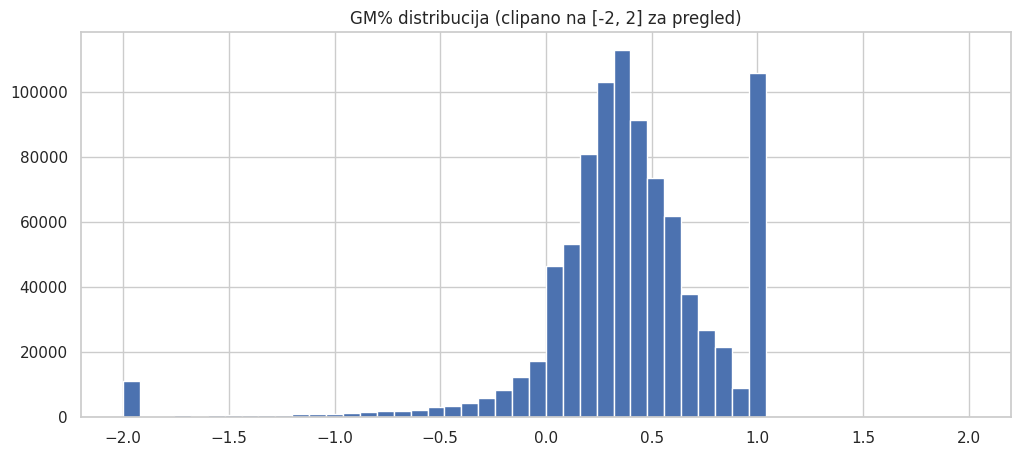

In [74]:
# Provjeri GM% distribuciju
print(df_4['GM%'].describe())
print(f'\nBroj null GM%: {df_4["GM%"].isna().sum()}')
print(f'\nBroj GM% > 1: {(df_4["GM%"] > 1).sum()}')
print(f'Broj GM% < -1: {(df_4["GM%"] < -1).sum()}')
print(f'Broj GM% < -5: {(df_4["GM%"] < -5).sum()}')
print(f'Broj GM% < -10: {(df_4["GM%"] < -10).sum()}')

import matplotlib.pyplot as plt
df_4['GM%'].clip(-2, 2).hist(bins=50)
plt.title('GM% distribucija (clipano na [-2, 2] za pregled)')
plt.show()

In [75]:
# Pogledaj najgore outliere
print('Najmanji GM%:')
display(df_4.nsmallest(10, 'GM%')[['Item Code', 'CustomerID', 'Invoiced price', 'Cost of part', 'GM%']])

print('\nNajveći GM%:')
display(df_4.nlargest(10, 'GM%')[['Item Code', 'CustomerID', 'Invoiced price', 'Cost of part', 'GM%']])

Najmanji GM%:


,Item Code,CustomerID,Invoiced price,Cost of part,GM%
683085,365143TM1,229575,0.0115,52080.1814,-4528710.4261
625878,358421TM1,229575,0.0114,46531.3860,-4081699.5263
715965,F18281-000-AA,108464,0.0100,6205.4715,-620546.1500
715966,F18281-000-AA,108464,0.0100,6205.4715,-620546.1500
908192,360756TM1,229575,0.0114,4653.1386,-408169.0526
577193,356234TM1,229395,0.0100,3098.1000,-309809.0000
183727,363683TM1,222134,0.0118,2174.8684,-184309.8814
1066586,416922TM1,222134,0.0118,2065.4000,-175032.8983
715971,F18281-000-AA,108464,0.0100,1227.8800,-122787.0000
1208323,365096,226113,0.0011,75.3220,-68473.5455



Najveći GM%:


,Item Code,CustomerID,Invoiced price,Cost of part,GM%
711558,2356-168,298276,31.7800,-3718.5738,118.0099
293501,PACA3311912400,2028,15.1700,-52.4300,4.4562
1077256,PACA3311912400,2028,15.1700,-52.1640,4.4386
68870,YB42-F1732-00,2042,1.7850,-2.4658,2.3814
225463,YB42-F1732-00,2042,1.7850,-2.4658,2.3814
519728,YB42-F1732-00,2042,1.7850,-2.4658,2.3814
593567,YB42-F1732-00,2042,1.7850,-2.4658,2.3814
822861,YB42-F1732-00,2042,1.7850,-2.4658,2.3814
906057,YB42-F1732-00,2042,1.7850,-2.4658,2.3814
1006113,YB42-F1732-00,2042,1.7850,-2.4658,2.3814


In [83]:
# Redovi di je cost drastično veći od cijene (npr. 100x+)
suspect = df_4[(df_4['Invoiced price'] > 0) & 
               (df_4['Cost of part'] > df_4['Invoiced price'] * 20)]
print(f"Suspect redova: {len(suspect)}")
print(suspect[['Item Code', 'CustomerID', 'Invoiced price', 'Cost of part', 'GM%']].head(20))

Suspect redova: 1563
             Item Code  CustomerID  Invoiced price  Cost of part      GM%
639            1998-LH      279068          0.0267        0.5820 -20.7978
700        BAR981-RM13        7782          4.6000    12312.6606      NaN
1188    SMA-1033772-06      133704         21.2768     1632.4665      NaN
1601  DEL449-8CH00-238       19421          1.2864       45.1826      NaN
1764            409435      230228          0.3824       18.8741 -48.3570
2347    SMA-1033705-OK      133704          4.7876      137.0608      NaN
2529     HEA383-010818       35098          0.2325        6.8168      NaN
2735  TES-1506323-00-A      258233          0.0771       28.3337      NaN
2752      12-19138-000       17912          0.3500       18.8900 -52.9714
2975    LX6B-S017C10-A       18833          0.2100       10.6750      NaN
3921       SIE-7419902       12629          0.6500      514.6799      NaN
4007        BIO021-657        7800          0.0618      136.9477      NaN
4331       B76-17

In [84]:
# Izbaci garbage data (cost 20x+ veći od cijene)
mask_garbage = (df_4['Invoiced price'] > 0) & (df_4['Cost of part'] > df_4['Invoiced price'] * 20)
print(f"Garbage redova: {mask_garbage.sum()}")
df_4 = df_4[~mask_garbage]

Garbage redova: 1563


In [63]:
raw_path = '../data/raw/LUMEN_DS.csv'
converted_path1 = '../data/raw/data1.csv'

if not os.path.exists(converted_path1):
    with open(raw_path, 'r', encoding='utf-16') as file:
        data = file.read()
    
    data = data.replace('"', '')
    
    with open(converted_path1, 'w', encoding='utf-8') as file:
        file.write(data)
    
    print('Konverzija gotova -> data1.csv')
else:
    print('data1.csv već postoji, preskačem konverziju')

DATE_COLS = [
    'Invoice Date',
    'Order Date',
    'Customer First Invoice Date',
    'Price last modified date in the ERP',
    'Born on date'
]

df1 = pd.read_csv(
    '../data/raw/data1.csv',
    encoding='utf-8',
    sep='|',
    low_memory=False,
    parse_dates=DATE_COLS
)

print(df1.shape)

# Pogledaj najgore outliere na početnim podacima
print('Najmanji GM%:')
display(df1.nsmallest(10, 'GM%')[['Item Code', 'CustomerID', 'Invoiced price', 'Cost of part', 'GM%']])

print('\nNajveći GM%:')
display(df1.nlargest(10, 'GM%')[['Item Code', 'CustomerID', 'Invoiced price', 'Cost of part', 'GM%']])

data1.csv već postoji, preskačem konverziju
(1294962, 33)
Najmanji GM%:


,Item Code,CustomerID,Invoiced price,Cost of part,GM%
683085,365143TM1,229575,0.0115,52080.1814,-4528710.4261
625878,358421TM1,229575,0.0114,46531.3860,-4081699.5263
715965,F18281-000-AA,108464,0.0100,6205.4715,-620546.1500
715966,F18281-000-AA,108464,0.0100,6205.4715,-620546.1500
908192,360756TM1,229575,0.0114,4653.1386,-408169.0526
577193,356234TM1,229395,0.0100,3098.1000,-309809.0000
1067162,317461TM2,230027,0.0100,2353.7957,-235378.5700
183727,363683TM1,222134,0.0118,2174.8684,-184309.8814
82195,317461TM1,230027,0.0100,1765.3468,-176533.6800
1066586,416922TM1,222134,0.0118,2065.4000,-175032.8983



Najveći GM%:


,Item Code,CustomerID,Invoiced price,Cost of part,GM%
884808,004367,217124,-0.0022,15.1391,6882.4091
29223,032647,216863,-0.0102,1.9863,195.7353
711558,2356-168,298276,31.7800,-3718.5738,118.0099
567320,700287,217288,-0.0130,0.2868,23.0615
1154079,700287,217288,-0.0330,0.2868,9.6909
753037,700190,217288,-0.0300,0.2128,8.0933
293501,PACA3311912400,2028,15.1700,-52.4300,4.4562
1077256,PACA3311912400,2028,15.1700,-52.1640,4.4386
68870,YB42-F1732-00,2042,1.7850,-2.4658,2.3814
225463,YB42-F1732-00,2042,1.7850,-2.4658,2.3814


In [85]:
df_4['GM%'] = df_4['GM%'].clip(-5, 1)

print('Nakon winsorize:')
print(df_4['GM%'].describe())

Nakon winsorize:
count   901263.0000
mean         0.3599
std          0.5847
min         -5.0000
25%          0.2104
50%          0.3833
75%          0.6058
max          1.0000
Name: GM%, dtype: float64


In [87]:
df_4.to_csv('../data/processed/data_clean_v1.csv', index=False)
print(f'Spremljeno! Shape: {df_4.shape}')

Spremljeno! Shape: (930361, 22)


---
## 5. Popunjavanje nedostajućih vrijednosti

In [38]:
DATE_COLS = [
    'Invoice Date',
    'Customer First Invoice Date'
]
df_5 = pd.read_csv('../data/processed/data_clean_v1.csv', low_memory=False, parse_dates=DATE_COLS)
print(f'Shape: {df_5.shape}')

Shape: (1079757, 24)


In [39]:
print(df_5.columns)
df_5.head(10)

Index(['Manufacturing Region', 'Manufacturing Location Code', 'Intercompany',
       'CustomerID', 'Customer industry', 'Customer Region',
       'Customer First Invoice Date', 'Top Customer Group', 'Item Code',
       'Product family', 'Product group', 'Make vs Buy',
       'Sales Channel - Internal', 'Sales Channel - External', 'Invoice Date',
       'Invoice #', 'Order #', 'Invoiced qty (shipped)', 'Ordered qty',
       'Invoiced price', 'Invoiced price (TX)', 'Cost of part', 'GM%',
       '# of unique products on a quote'],
      dtype='object')


,Manufacturing Region,Manufacturing Location Code,Intercompany,CustomerID,Customer industry,Customer Region,Customer First Invoice Date,Top Customer Group,Item Code,Product family,Product group,Make vs Buy,Sales Channel - Internal,Sales Channel - External,Invoice Date,Invoice #,Order #,Invoiced qty (shipped),Ordered qty,Invoiced price,Invoiced price (TX),Cost of part,GM%,# of unique products on a quote
0,North America,N7,NO,230494,IC012,North America,2007-08-08,OTHER,034903,PF002,PC026,BUY,900,900,2019-11-26,16808190,82915.0000,1000.0000,1000.0000,0.1400,0.1400,0.0257,0.8164,3.0000
1,Asia,N13,NO,223839,IC000,Asia,2003-09-08,OTHER,309146,PF002,PC026,BUY,230,230,2020-03-20,16823988,98093.0000,2000.0000,5000.0000,0.2000,0.2000,0.0000,1.0000,1.0000
2,Asia,N13,NO,223839,IC000,Asia,2003-09-08,OTHER,309146,PF002,PC026,BUY,230,230,2020-03-20,16818712,98093.0000,1230.0000,5000.0000,0.2000,0.2000,0.0000,1.0000,1.0000
3,Asia,N13,NO,223839,IC000,Asia,2003-09-08,OTHER,309146,PF002,PC026,BUY,230,230,2020-03-17,16818284,98093.0000,1770.0000,5000.0000,0.2000,0.2000,0.0000,1.0000,1.0000
4,Asia,N13,NO,224307,IC000,Asia,2011-05-27,OTHER,343372,PF002,SF002,MANUFACTURED,230,230,2018-09-29,16964668,513470.0000,4000.0000,4000.0000,2.7800,2.7800,0.0000,1.0000,6.0000
5,Asia,N12,NO,224029,IC000,Asia,2005-01-31,OTHER,348716,PF002,PC013,MANUFACTURED,11103,11103,2020-06-15,17028488,73572.0000,15000.0000,15000.0000,2.5800,2.5800,0.0000,1.0000,1.0000
6,Asia,N12,NO,224029,IC000,Asia,2005-01-31,OTHER,352311,PF002,PC013,MANUFACTURED,11103,11103,2020-01-09,17006210,91617.0000,500.0000,500.0000,2.4700,2.4700,0.0000,1.0000,1.0000
7,Asia,N13,NO,224600,IC007,Asia,2012-04-10,STAR,357269,PF002,PC013,MANUFACTURED,DG_0029,DG_0029,2019-06-02,16981093,526717.0000,2000.0000,2000.0000,1.8000,1.8000,0.0000,1.0000,2.0000
8,Asia,N12,NO,231278,IC000,Asia,2005-03-10,OTHER,357314,PF002,PC013,MANUFACTURED,11103,11103,2020-03-20,17011244,102429.0000,500.0000,500.0000,2.2600,2.2600,0.0000,1.0000,5.0000
9,Asia,N13,NO,223638,IC009,Asia,2018-04-11,OTHER,357325,PF002,PC019,MANUFACTURED,SZ_13748,SZ_13748,2018-08-22,16718215,509919.0000,19.0000,21.0000,248.9996,1705.0000,117.9172,0.5264,1.0000


In [40]:
results = {}

for col in df_5.columns:
    issues = {}

    null_count = df_5[col].isna().sum()
    if null_count > 0:
        issues['NaN/null'] = null_count

    if df_5[col].dtype == 'object':
        empty_count = (df_5[col] == '').sum()
        if empty_count > 0:
            issues['empty string'] = empty_count

        unknown_count = (df_5[col].str.lower() == 'unknown').sum()
        if unknown_count > 0:
            issues['Unknown'] = unknown_count

        nan_str_count = (df_5[col].str.lower() == 'nan').sum()
        if nan_str_count > 0:
            issues['NaN string'] = nan_str_count

    if issues:
        results[col] = issues

for col, issues in results.items():
    total = sum(issues.values())
    print(f'\n{col} (ukupno: {total})')
    for issue_type, count in issues.items():
        print(f'{issue_type}: {count}')


Manufacturing Region (ukupno: 23328)
NaN/null: 23328

Manufacturing Location Code (ukupno: 22786)
NaN/null: 22786

Customer Region (ukupno: 87)
NaN/null: 87

Product group (ukupno: 63900)
NaN/null: 63900

Make vs Buy (ukupno: 13865)
NaN/null: 13865

Sales Channel - Internal (ukupno: 23506)
NaN/null: 23506

Sales Channel - External (ukupno: 23506)
NaN/null: 23506

Order # (ukupno: 33381)
NaN/null: 33381

Ordered qty (ukupno: 33381)
NaN/null: 33381

Invoiced price (TX) (ukupno: 8337)
NaN/null: 8337

Cost of part (ukupno: 22482)
NaN/null: 22482

GM% (ukupno: 65441)
NaN/null: 65441

# of unique products on a quote (ukupno: 33381)
NaN/null: 33381


In [41]:
# Zamijeni prazne stringove s NaN za konzistentnost
df_5 = df_5.replace('', np.nan)

# Kategorički stupci — popuni s 'Unknown'
fill_unknown = [
    'Manufacturing Region',
    'Manufacturing Location Code',
    'Intercompany',
    'Customer industry',
    'Customer Region',
    'Top Customer Group',
    'Product family',
    'Product group',
    'Make vs Buy',
    'Sales Channel - Internal',
    'Sales Channel - External'
]

for col in fill_unknown:
    if col in df_5.columns:
        n_filled = df_5[col].isna().sum()
        df_5[col] = df_5[col].fillna('Unknown')
        if n_filled > 0:
            print(f'{col}: popunjeno {n_filled} redova s "Unknown"')

Manufacturing Region: popunjeno 23328 redova s "Unknown"
Manufacturing Location Code: popunjeno 22786 redova s "Unknown"
Customer Region: popunjeno 87 redova s "Unknown"
Product group: popunjeno 63900 redova s "Unknown"
Make vs Buy: popunjeno 13865 redova s "Unknown"
Sales Channel - Internal: popunjeno 23506 redova s "Unknown"
Sales Channel - External: popunjeno 23506 redova s "Unknown"


In [42]:
results = {}

for col in df_5.columns:
    issues = {}

    null_count = df_5[col].isna().sum()
    if null_count > 0:
        issues['NaN/null'] = null_count

    if df_5[col].dtype == 'object':
        empty_count = (df_5[col] == '').sum()
        if empty_count > 0:
            issues['empty string'] = empty_count

        unknown_count = (df_5[col].str.lower() == 'unknown').sum()
        if unknown_count > 0:
            issues['Unknown'] = unknown_count

        nan_str_count = (df_5[col].str.lower() == 'nan').sum()
        if nan_str_count > 0:
            issues['NaN string'] = nan_str_count

    if issues:
        results[col] = issues

for col, issues in results.items():
    total = sum(issues.values())
    print(f'\n{col} (ukupno: {total})')
    for issue_type, count in issues.items():
        print(f'{issue_type}: {count}')


Manufacturing Region (ukupno: 23328)
Unknown: 23328

Manufacturing Location Code (ukupno: 22786)
Unknown: 22786

Customer Region (ukupno: 87)
Unknown: 87

Product group (ukupno: 63900)
Unknown: 63900

Make vs Buy (ukupno: 13865)
Unknown: 13865

Sales Channel - Internal (ukupno: 23506)
Unknown: 23506

Sales Channel - External (ukupno: 23506)
Unknown: 23506

Order # (ukupno: 33381)
NaN/null: 33381

Ordered qty (ukupno: 33381)
NaN/null: 33381

Invoiced price (TX) (ukupno: 8337)
NaN/null: 8337

Cost of part (ukupno: 22482)
NaN/null: 22482

GM% (ukupno: 65441)
NaN/null: 65441

# of unique products on a quote (ukupno: 33381)
NaN/null: 33381


In [43]:
n_before = df_5['Invoiced price (TX)'].isna().sum()
df_5['Invoiced price (TX)'] = df_5['Invoiced price (TX)'].fillna(df_5['Invoiced price'])
print(f'Invoiced price (TX): popunjeno {n_before} redova s Invoiced price')

Invoiced price (TX): popunjeno 8337 redova s Invoiced price


In [44]:
n_before = df_5['Cost of part'].isna().sum()
print(f'Cost of part null: {n_before} redova')

Cost of part null: 22482 redova


In [45]:
median_cost_by_item = df_5.groupby('Item Code')['Cost of part'].median()
df_5['Cost of part'] = df_5['Cost of part'].fillna(df_5['Item Code'].map(median_cost_by_item))
print(f'Nakon Item Code: {df_5["Cost of part"].isna().sum()} nullova')

Nakon Item Code: 22482 nullova


In [46]:
avg_gm_by_group = df_5.groupby('Product group')['GM%'].median()
estimated = df_5['Invoiced price'] * (1 - df_5['Product group'].map(avg_gm_by_group))
df_5['Cost of part'] = df_5['Cost of part'].fillna(estimated)
print(f'Nakon GM% procjene po Product group: {df_5["Cost of part"].isna().sum()} nullova')

Nakon GM% procjene po Product group: 0 nullova


In [47]:
n_before = df_5['GM%'].isna().sum()

# Izračunaj iz cijene i troška
df_5['GM%'] = df_5['GM%'].fillna(
    (df_5['Invoiced price'] - df_5['Cost of part']) / df_5['Invoiced price']
)

# Winsorize opet jer novi GM% mogu biti outlieri
df_5['GM%'] = df_5['GM%'].clip(-5, 1)

n_after = df_5['GM%'].isna().sum()
print(f'GM%: popunjeno {n_before - n_after} redova')
print(f'GM% još uvijek null: {n_after}')
print(df_5['GM%'].describe())

GM%: popunjeno 44102 redova
GM% još uvijek null: 21339
count   1058418.0000
mean          0.3519
std           0.7802
min          -5.0000
25%           0.2265
50%           0.4007
75%           0.6616
max           1.0000
Name: GM%, dtype: float64


In [48]:
still_null_gm = df_5[df_5['GM%'].isna()]

print(f'Invoiced price null u tim redovima: {still_null_gm["Invoiced price"].isna().sum()}')
print(f'Cost of part null u tim redovima: {still_null_gm["Cost of part"].isna().sum()}')
print(f'Invoiced price == 0 u tim redovima: {(still_null_gm["Invoiced price"] == 0).sum()}')

Invoiced price null u tim redovima: 0
Cost of part null u tim redovima: 0
Invoiced price == 0 u tim redovima: 21339


In [49]:
print(f'GM% null ostavljamo: {df_5["GM%"].isna().sum()}')
print(f'To je {df_5["GM%"].isna().sum() / len(df_5) * 100:.1f}% dataseta')

GM% null ostavljamo: 21339
To je 2.0% dataseta


---
## 6. Enkodiranje kategoričkih varijabli

Za ML modele trebamo numeričke vrijednosti. Koristimo dvije strategije:
- **Label encoding** za ordinalne ili visoko-kardinalne varijable
- **One-hot encoding** za nisko-kardinalne (< 10 kategorija)

In [ ]:
from sklearn.preprocessing import LabelEncoder

df_encoded = df.copy()

# --- LABEL ENCODING (visoka kardinalnost ili redoslijed nije bitan) ---
label_encode_cols = [
    'CustomerID',
    'Item Code',
    'Manufacturing Location Code',
    'Sales Channel - Internal',
    'Sales Channel - External',
    'Top Customer Group',    # OTHER=0, STAR=1
    'Intercompany',          # NO=0, YES=1
    'Make vs Buy',           # BUY=0, MANUFACTURED=1
]

le_dict = {}  # spremamo enkodere za inverse_transform kasnije

for col in label_encode_cols:
    if col in df_encoded.columns:
        le = LabelEncoder()
        df_encoded[col + '_enc'] = le.fit_transform(df_encoded[col].astype(str))
        le_dict[col] = le
        print(f'{col}: {df_encoded[col].nunique()} kategorija → label encoded')

# --- ONE-HOT ENCODING (niska kardinalnost) ---
ohe_cols = [
    'Manufacturing Region',   # North America, Asia, Europe
    'Customer Region',        # North America, Asia, Europe  
    'Product family',         # PF000, PF001, PF002
]

for col in ohe_cols:
    if col in df_encoded.columns:
        dummies = pd.get_dummies(df_encoded[col], prefix=col, drop_first=False)
        df_encoded = pd.concat([df_encoded, dummies], axis=1)
        print(f'{col}: one-hot → {dummies.shape[1]} novih stupaca')

print(f'\nShape nakon enkodiranja: {df_encoded.shape}')

In [ ]:
# Customer industry enkodiranje (IC000, IC001... → numerički)
# Izvuci broj iz stringa
if 'Customer industry' in df_encoded.columns:
    df_encoded['customer_industry_num'] = (
        df_encoded['Customer industry']
        .str.extract(r'(\d+)')
        .astype(float)
    )
    print('Customer industry → customer_industry_num ✓')
    print(df_encoded['customer_industry_num'].value_counts())

---
## 7. Feature Engineering — izvedene značajke

Ovo je ključni korak — kreiramo varijable koje modelu daju kontekst o kupcu i ponašanju.

In [ ]:
# 7a. Vremenski featuri iz Invoice Date
df_encoded['invoice_year'] = df_encoded['Invoice Date'].dt.year
df_encoded['invoice_month'] = df_encoded['Invoice Date'].dt.month
df_encoded['invoice_quarter'] = df_encoded['Invoice Date'].dt.quarter
df_encoded['invoice_dayofweek'] = df_encoded['Invoice Date'].dt.dayofweek

print('Vremenski featuri dodani ✓')

In [ ]:
# 7b. Customer tenure — koliko dugo je kupac aktivan (u danima)
reference_date = df_encoded['Invoice Date'].max()
df_encoded['customer_tenure_days'] = (
    reference_date - df_encoded['Customer First Invoice Date']
).dt.days

print('Customer tenure izračunat ✓')
print(df_encoded['customer_tenure_days'].describe())

In [ ]:
# 7c. Revenue po liniji (qty * price)
df_encoded['line_revenue'] = (
    df_encoded['Invoiced qty (shipped)'] * df_encoded['Invoiced price']
)

# 7d. Gross profit po liniji
df_encoded['line_gross_profit'] = df_encoded['line_revenue'] * df_encoded['GM%']

print('Revenue i gross profit featuri dodani ✓')

In [ ]:
# 7e. Customer-level aggregate featuri
# Ovo je srž za customer segmentaciju!
customer_agg = df_encoded.groupby('CustomerID').agg(
    total_revenue=('line_revenue', 'sum'),
    total_orders=('Invoice #', 'nunique'),
    total_items=('Item Code', 'nunique'),
    avg_order_value=('line_revenue', 'mean'),
    avg_gm=('GM%', 'mean'),
    n_product_families=('Product family', 'nunique'),
    n_product_groups=('Product group', 'nunique'),
    customer_tenure_days=('customer_tenure_days', 'first'),
    customer_region=('Customer Region', 'first'),
    customer_industry=('Customer industry', 'first'),
    top_customer_group=('Top Customer Group', 'first'),
).reset_index()

print(f'Customer aggregate tablica: {customer_agg.shape}')
display(customer_agg.head())

In [ ]:
# 7f. Vizualizacija distribucija ključnih featura
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

customer_agg['total_revenue'].apply(lambda x: np.log1p(x)).hist(
    bins=40, ax=axes[0,0], color='steelblue')
axes[0,0].set_title('Log(Total Revenue) po kupcu')

customer_agg['total_orders'].hist(bins=40, ax=axes[0,1], color='steelblue')
axes[0,1].set_title('Broj narudžbi po kupcu')

customer_agg['total_items'].hist(bins=40, ax=axes[0,2], color='steelblue')
axes[0,2].set_title('Broj unikatnih proizvoda po kupcu')

customer_agg['avg_gm'].hist(bins=40, ax=axes[1,0], color='salmon')
axes[1,0].set_title('Prosječni GM% po kupcu')

customer_agg['customer_tenure_days'].hist(bins=40, ax=axes[1,1], color='steelblue')
axes[1,1].set_title('Customer Tenure (dani)')

customer_agg['n_product_groups'].hist(bins=30, ax=axes[1,2], color='green', alpha=0.7)
axes[1,2].set_title('Broj product grupe po kupcu')

plt.suptitle('Distribucije ključnih customer featura', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

In [ ]:
# 7g. Product co-occurrence matrica (osnova za cross-sell)
# Grupiraj po Invoice # — koji proizvodi se pojavljuju na istoj fakturi?
invoice_items = df_encoded.groupby('Invoice #')['Product group'].apply(
    lambda x: list(x.dropna().unique())
).reset_index()
invoice_items.columns = ['invoice_id', 'product_groups']

# Filtriraj fakture s više od jednog produkta (cross-sell prilike)
multi_product = invoice_items[invoice_items['product_groups'].apply(len) > 1]
print(f'Fakture s 1 produktom: {(invoice_items["product_groups"].apply(len) == 1).sum():,}')
print(f'Fakture s 2+ produkata: {len(multi_product):,}')
print(f'% multi-product faktura: {len(multi_product)/len(invoice_items)*100:.1f}%')
display(multi_product.head(5))

---
## 8. Korelacijska analiza numeričkih featura

In [ ]:
num_features = [
    'Invoiced qty (shipped)', 'Invoiced price', 'Cost of part',
    'GM%', 'line_revenue', 'customer_tenure_days',
    'invoice_month', 'invoice_quarter'
]

existing_num = [c for c in num_features if c in df_encoded.columns]
corr = df_encoded[existing_num].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, linewidths=0.5)
plt.title('Korelacijska matrica numeričkih featura')
plt.tight_layout()
plt.show()

---
## 9. Finalni dataset — spremi za modeliranje

In [ ]:
# Finalni pregled
print('=== FINALNI DATASET ===')
print(f'Shape: {df_encoded.shape}')
print(f'Nullovi: {df_encoded.isnull().sum().sum()}')
print(f'\nStupci:')
for col in df_encoded.columns:
    print(f'  {col}: {df_encoded[col].dtype}')

In [ ]:
# Spremi očišćeni dataset
df_encoded.to_csv('../data/processed/data_clean.csv', index=False)
customer_agg.to_csv('../data/processed/customer_features.csv', index=False)
invoice_items.to_csv('../data/processed/invoice_items.csv', index=False)

print('Spremljeno ✓')
print('  → data/processed/data_clean.csv')
print('  → data/processed/customer_features.csv')
print('  → data/processed/invoice_items.csv')

---
## Sažetak — što smo napravili

| Korak | Akcija |
|-------|--------|
| Stupci | Uklonili smo 12 redudantnih stupaca (cleaner.py) |
| Intercompany | Filtrirali smo Intercompany=YES transakcije van modela |
| Redovi | Uklonili smo redove bez Item Code / CustomerID / Invoiced price |
| Redovi | Uklonili smo negativne cijene i količine (credit note-ovi) |
| GM% | Winsorized na [-5, 1] za outliere |
| Nullovi | Kategorički → 'Unknown', numerički → medijan |
| Enkodiranje | Label encoding za visoko-kardinalne, OHE za nisko-kardinalne |
| Novi featuri | Tenure, revenue, gross profit, vremenski featuri |
| Agregati | Customer-level tablica za segmentaciju |
| Co-occurrence | Invoice-items tablica za market basket analysis |

**Sljedeći korak → `02_customer_segmentation.ipynb`**